In [ ]:
!pip install optuna
# 1. Gerekli Kütüphanelerin İçe Aktarılması
import pandas as pd
import numpy as np
import os
import joblib
from google.colab import drive

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, matthews_corrcoef, f1_score, roc_curve, auc
from sklearn.model_selection import StratifiedKFold

import tensorflow as tf
from tensorflow.keras.models import Sequential, save_model
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

!pip install optuna # Optuna kütüphanesini yükleyin
import optuna # Bayesian optimizasyon için
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# 2. Google Drive'ı Bağlama
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 29.4 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np

# 3. Verileri Yükleme
train_path = '/content/drive/MyDrive/data/ai-ready-data/train_selected_shap.csv'
test_path = '/content/drive/MyDrive/data/ai-ready-data/test_selected_shap.csv'

print("Veriler yükleniyor, lütfen bekleyin...")
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print(f"Eğitim verisi boyutu: {train_df.shape}")
print(f"Test verisi boyutu: {test_df.shape}")

# 4. Özellikleri (X) ve Etiketleri (y) Ayırma
X_train = train_df.drop('Label', axis=1).values
y_train = train_df['Label'].values

X_test = test_df.drop('Label', axis=1).values
y_test = test_df['Label'].values

# Sınıf sayısını belirleme (Modelin çıkış katmanı için)
num_classes = len(np.unique(y_train))
print(f"Toplam Sınıf Sayısı: {num_classes}")
print(f"Mevcut Sınıf Etiketleri: {np.unique(y_train)}")

# 5. 1D-CNN İçin Veriyi Yeniden Boyutlandırma (GÜVENLİ RESHAPE)
# Veri dataframe'den ilk çekildiğinde her zaman 2 boyutludur: (Örnek Sayısı, Özellik Sayısı)
# Özellik sayısını sabit bir değişkene alıyoruz ki hücre tekrar çalışırsa boyutlar kaymasın.
feature_count = train_df.shape[1] - 1 # Label kolonu hariç sütun sayısı (Örn: 64)

# -1 parametresi numpy'a "örnek sayısını (satır) kendin hesapla" der.
# Bu yapı, kodu 10 kere çalıştırsanız bile sonucun hep (N, 64, 1) kalmasını sağlar.
X_train = X_train.reshape(-1, feature_count, 1)
X_test  = X_test.reshape(-1, feature_count, 1)

print(f"1D-CNN için X_train boyutu: {X_train.shape}")
print(f"1D-CNN için X_test boyutu: {X_test.shape}")
# print("--- BLOK 1 TAMAMLANDI ---")

Veriler yükleniyor, lütfen bekleyin...
Eğitim verisi boyutu: (1765620, 38)
Test verisi boyutu: (756695, 38)
Toplam Sınıf Sayısı: 8
Mevcut Sınıf Etiketleri: [0 1 2 3 4 5 6 7]
1D-CNN için X_train boyutu: (1765620, 37, 1)
1D-CNN için X_test boyutu: (756695, 37, 1)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[OK] Klasörler hazır:
  /content/drive/MyDrive/data/1d-cnn_best_2
  /content/drive/MyDrive/data/1d-cnn_best_2/models
[OK] Veri yüklendi ve 1D-CNN için yeniden şekillendirildi.
     Train boyutu: (1765620, 37, 1), Test boyutu: (756695, 37, 1)


[SAVED] /content/drive/MyDrive/data/1d-cnn_best_2/models/model_architecture.txt

   10-FOLD CROSS VALIDATION BASLIYOR

          FOLD 1 / 10
Epoch 1/50
6208/6208 ━━━━━━━━━━━━━━━━━━━━ 36s 4ms/step - accuracy: 0.9873 - loss: 0.0461 - val_accuracy: 0.9955 - val_loss: 0.0192
Epoch 2/50
6208/6208 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - accuracy: 0.9950 - loss: 0.0186 - val_accuracy: 0.9967 - val_loss: 0.0133
Epoch 3/50
6208/6208 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - accuracy: 0.9960 - loss: 0.0153 - val_accuracy: 0.9972 - val_loss: 0.0117
Epoch 4/50
6208/6208 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - accuracy: 0.9965 - loss: 0.0138 - val_accuracy: 0.9973 - val_loss: 0.0105
Epoch 5/50
6208/6208 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - accuracy: 0.9966 - loss: 0.0130 - val_accuracy: 0.9974 - val_loss: 0.0107
Epoch 6/50
6208/6208 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - accuracy: 0.9968 - loss: 0.0120 - val_accuracy: 0.9975 - val_loss: 0.0095
Epoch 7/50
6208/6208 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - accuracy: 0.9969

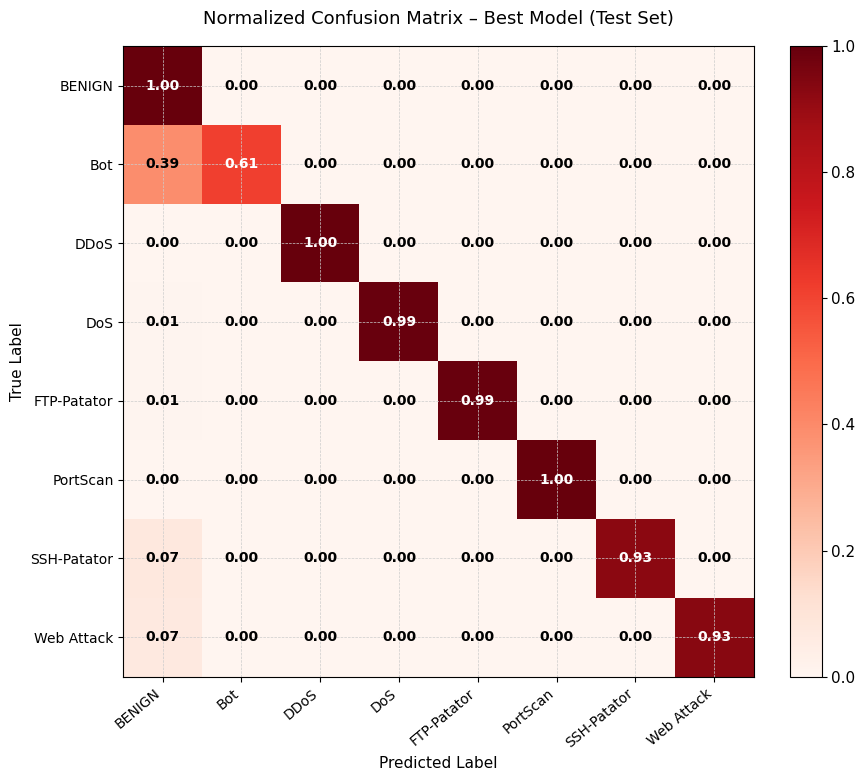

  [SAVED] /content/drive/MyDrive/data/1d-cnn_best_2/loss_plot.png


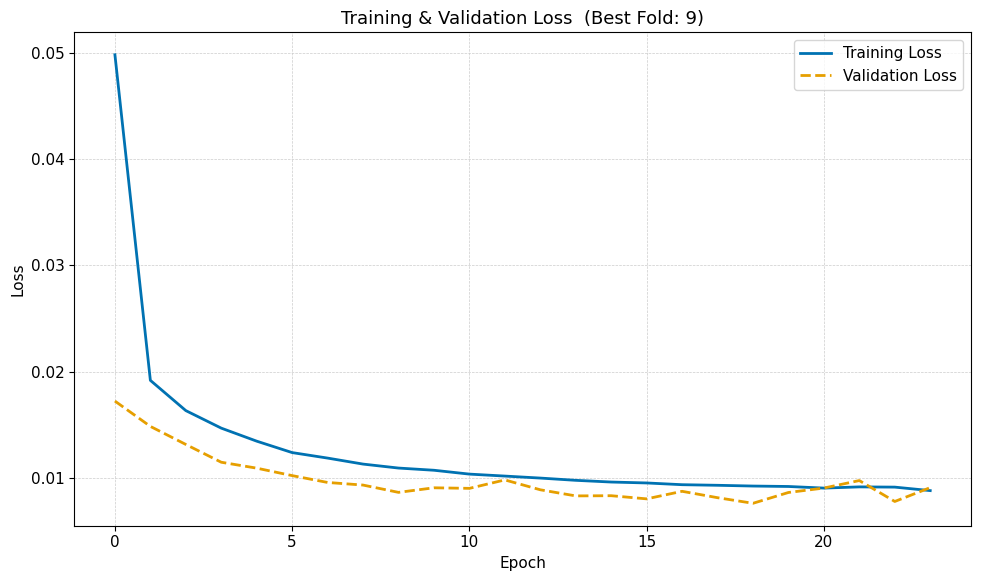

  [SAVED] /content/drive/MyDrive/data/1d-cnn_best_2/accuracy_plot.png


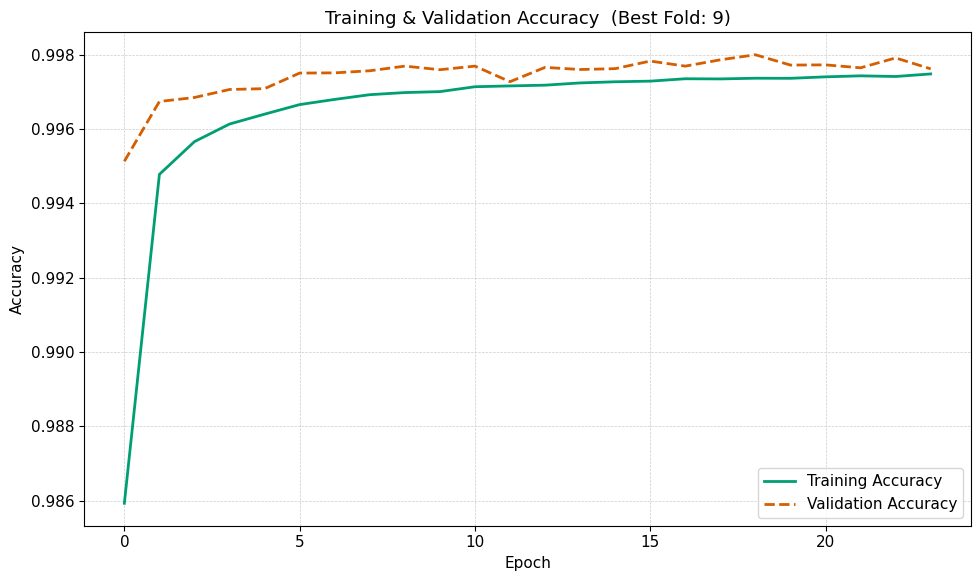

  [SAVED] /content/drive/MyDrive/data/1d-cnn_best_2/fold_metrics.png


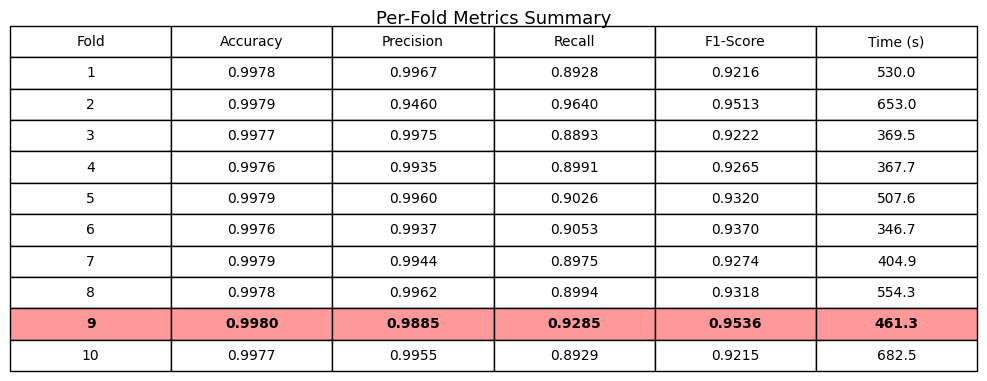

  [SAVED] /content/drive/MyDrive/data/1d-cnn_best_2/roc_curves.png


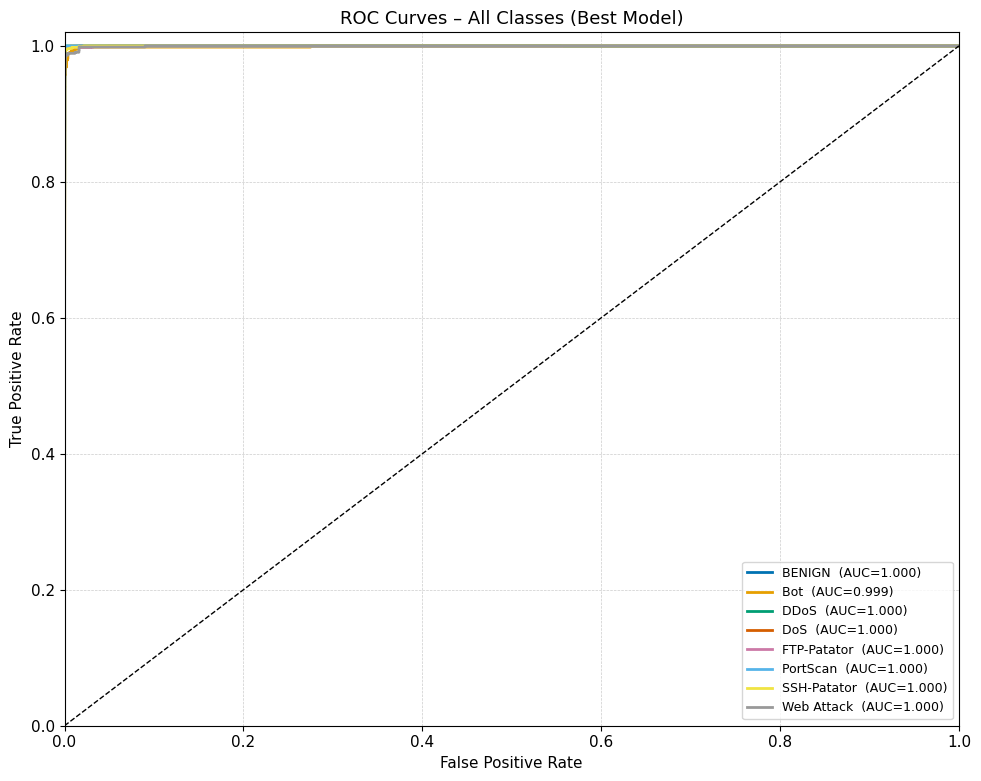

  [SAVED] /content/drive/MyDrive/data/1d-cnn_best_2/precision_recall_curves.png


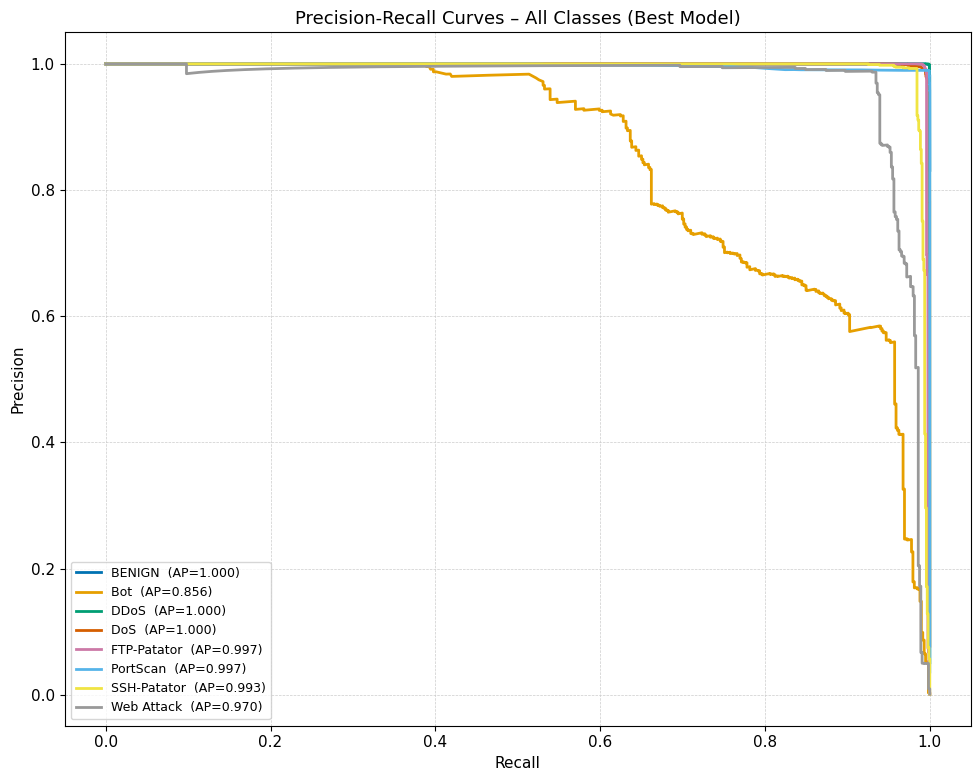

  [SAVED] /content/drive/MyDrive/data/1d-cnn_best_2/class_metrics_bar.png


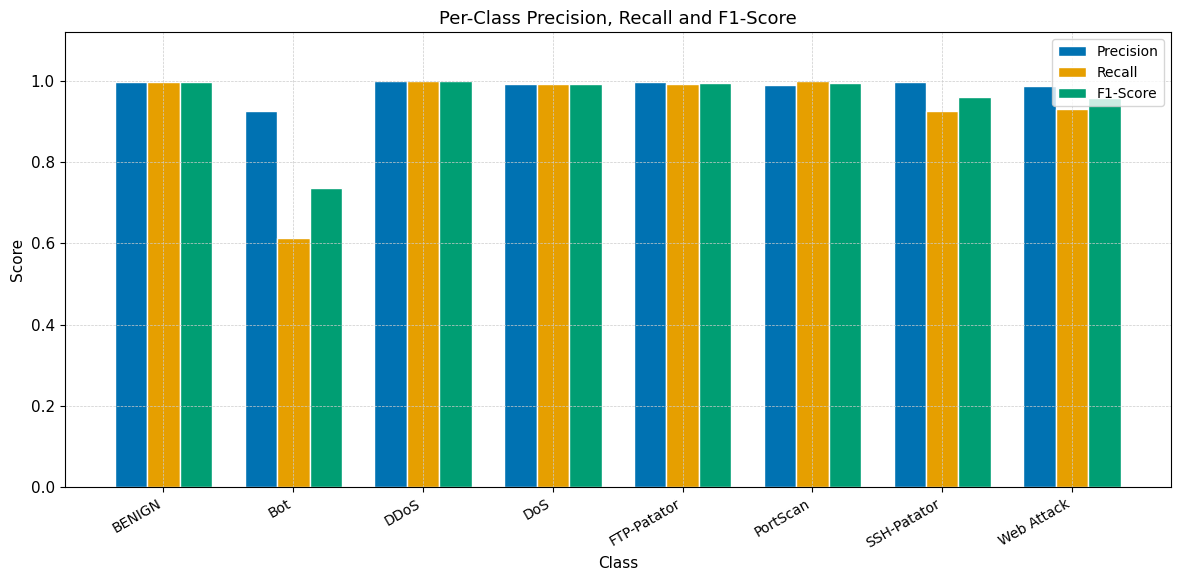

[SAVED] /content/drive/MyDrive/data/1d-cnn_best_2/metrics_summary.txt
[SAVED] /content/drive/MyDrive/data/1d-cnn_best_2/final_report.txt

  TUM CIKTILAR KAYDEDILDI –  TAMAMLANDI
  Drive klasoru : /content/drive/MyDrive/data/1d-cnn_best_2
  Toplam sure   : 5001.2s  (83.35 dk)
  *** EN IYI FOLD: 9  (Macro F1: 0.9536) ***


In [ ]:
# ============================================================
#  1D-CNN  –  Google Colab Full Training Script
#  Tez çalışması için profesyonel çıktılarla 10-Fold CV
# ============================================================

# ── 0. Colab kurulumu ──────────────────────────────────────
%matplotlib inline
import os, time, io, warnings
warnings.filterwarnings('ignore')

# Google Drive bağlantısı (Colab ortamında çalışıyorsa)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR    = '/content/drive/MyDrive/data/1d-cnn_best_2'
except ImportError:
    print("Colab ortamı bulunamadı. Lokal dizin kullanılacak.")
    BASE_DIR    = './1d-cnn_best_2'

# ── 1. Klasör yapısını oluştur ─────────────────────────────
MODELS_DIR  = os.path.join(BASE_DIR, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)
print(f"[OK] Klasörler hazır:\n  {BASE_DIR}\n  {MODELS_DIR}")

# ── 2. Kütüphaneler ────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv1D, BatchNormalization,
                                     MaxPooling1D, Dropout, Flatten, Dense)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (f1_score, classification_report,
                              confusion_matrix, precision_score,
                              recall_score, roc_curve, auc,
                              precision_recall_curve,
                              average_precision_score)
from sklearn.preprocessing import label_binarize
import itertools

# Sınıf isimleri
CLASS_NAMES = ['BENIGN', 'Bot', 'DDoS', 'DoS',
               'FTP-Patator', 'PortScan', 'SSH-Patator', 'Web Attack']

# Colorblind-friendly palet
CB_COLORS = ['#0072B2','#E69F00','#009E73','#D55E00',
             '#CC79A7','#56B4E9','#F0E442','#999999']

# ── 3. Grafik ayarları (global) ────────────────────────────
plt.rcParams.update({
    'font.size'        : 13,
    'axes.titlesize'   : 15,
    'axes.labelsize'   : 13,
    'xtick.labelsize'  : 11,
    'ytick.labelsize'  : 11,
    'legend.fontsize'  : 11,
    'figure.dpi'       : 100,
    'axes.grid'        : True,
    'grid.color'       : '#cccccc',
    'grid.linewidth'   : 0.5,
    'grid.linestyle'   : '--',
})
SAVE_DPI = 300

# ── 4. Yardımcı kaydetme fonksiyonu ───────────────────────
def savefig(fig, filename):
    path = os.path.join(BASE_DIR, filename)
    fig.savefig(path, dpi=SAVE_DPI, bbox_inches='tight')
    print(f"  [SAVED] {path}")


# -------------------------------------------

num_classes = len(CLASS_NAMES)
assert X_train.shape[0] == y_train.shape[0], "X_train ve y_train boyutları uyuşmuyor!"

# KRİTİK DÜZELTME: 1D-CNN için veriyi 3 boyutlu hale getirme (Gözlem, Özellik, Kanal)
#X_train = np.expand_dims(X_train, axis=-1)
#X_test  = np.expand_dims(X_test, axis=-1)

print(f"[OK] Veri yüklendi ve 1D-CNN için yeniden şekillendirildi.")
print(f"     Train boyutu: {X_train.shape}, Test boyutu: {X_test.shape}")

# ── 6. Model Mimarisi ──────────────────────────────────────
def create_1d_cnn(input_shape, num_classes):
    model = Sequential([
        # Conv Layer 01
        Conv1D(filters=32, kernel_size=2, activation='relu', padding='same', input_shape=input_shape),

        # Conv Layer 02
        Conv1D(filters=16, kernel_size=2, activation='relu', padding='valid'),

        # Conv Layer 03
        Conv1D(filters=16, kernel_size=2, activation='relu', padding='valid'),

        # Conv Layer 04
        Conv1D(filters=16, kernel_size=2, activation='relu', padding='valid'),

        # Conv Layer 05
        Conv1D(filters=16, kernel_size=2, activation='relu', padding='valid'),

        # Dropout
        Dropout(0.5),

        # Max Pooling
        MaxPooling1D(pool_size=2),

        # Flatten
        Flatten(),

        # Dense Layers
        Dense(100, activation='relu'),
        Dense(75, activation='relu'),
        Dense(50, activation='relu'),
        Dense(25, activation='relu'),

        # Output Layer (Makalede 5 sınıftı, sizin kodunuzdaki sınıf sayısına (num_classes) uyarlandı)
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(), # Makalede öğrenme oranı belirtilmemiş, default 0.001 kullanılır
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Model mimarisini kaydet
_tmp_model = create_1d_cnn((X_train.shape[1], 1), num_classes)
arch_path  = os.path.join(MODELS_DIR, 'model_architecture.txt')
with open(arch_path, 'w') as f:
    _tmp_model.summary(print_fn=lambda x: f.write(x + '\n'))
print(f"[SAVED] {arch_path}")
total_params = _tmp_model.count_params()
del _tmp_model

# ── 7. Çapraz Doğrulama (10-Fold) ─────────────────────────
n_splits   = 10
skf        = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
BATCH_SIZE = 256
EPOCHS     = 50

fold_results = []
best_model   = None
best_f1      = 0.0
best_fold_no = -1
best_history = None

total_start = time.time()

print(f"\n{'='*52}")
print(f"   10-FOLD CROSS VALIDATION BASLIYOR")
print(f"{'='*52}")

# y_train için StratifiedKFold kullanırken 1D dizi (flatten) beklendiğinden emin oluyoruz
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train.squeeze(), y_train)):
    fold_num = fold + 1
    print(f"\n{'='*52}")
    print(f"          FOLD {fold_num} / {n_splits}")
    print(f"{'='*52}")

    X_tr, X_val = X_train[train_idx], X_train[val_idx]
    y_tr, y_val = y_train[train_idx], y_train[val_idx]

    input_shape = (X_train.shape[1], 1)
    model = create_1d_cnn(input_shape, num_classes)

    ckpt_path = os.path.join(MODELS_DIR, f'fold_{fold_num}_best_model.keras')
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        ModelCheckpoint(ckpt_path, monitor='val_loss',
                        save_best_only=True, mode='min', verbose=0)
    ]

    fold_start = time.time()
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )
    fold_elapsed = time.time() - fold_start

    # Değerlendirme
    y_pred_probs = model.predict(X_val, verbose=0)
    y_pred       = np.argmax(y_pred_probs, axis=1)

    acc  = np.mean(y_pred == y_val)
    f1   = f1_score(y_val, y_pred, average='macro', zero_division=0)
    prec = precision_score(y_val, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_val, y_pred, average='macro', zero_division=0)

    fold_results.append({
        'fold'     : fold_num,
        'accuracy' : acc,
        'f1'       : f1,
        'precision': prec,
        'recall'   : rec,
        'time_s'   : fold_elapsed,
        'history'  : history.history
    })

    print(f"\n-> Fold {fold_num} | Acc: {acc:.4f} | F1: {f1:.4f} "
          f"| Prec: {prec:.4f} | Rec: {rec:.4f} | Time: {fold_elapsed:.1f}s")

    if f1 > best_f1:
        best_f1       = f1
        best_model    = model
        best_fold_no  = fold_num
        best_history  = history.history

    if fold_num > 1:
        current_best = max(fold_results, key=lambda x: x['f1'])
        print(f"\033[1;31m  *** BEST FOLD SO FAR: FOLD {current_best['fold']} "
              f"(Macro F1: {current_best['f1']:.4f}) ***\033[0m")

total_elapsed = time.time() - total_start

# ── 8. En iyi ve son model kaydetme ───────────────────────
best_model.save(os.path.join(MODELS_DIR, 'best_overall_model.keras'))
best_model.save_weights(os.path.join(MODELS_DIR, 'best_weights.weights.h5'))
print(f"\n[SAVED] Tüm model dosyaları {MODELS_DIR} altına kaydedildi.")

# ── 9. Test seti – nihai değerlendirme ────────────────────
print("\nEn iyi model ile X_test degerlendiriliyor...")
y_test_probs = best_model.predict(X_test, verbose=0)
y_test_pred  = np.argmax(y_test_probs, axis=1)

test_report  = classification_report(y_test, y_test_pred,
                                     target_names=CLASS_NAMES)
print("\n--- NIHAI TEST SINIFLANDIRMA RAPORU ---")
print(test_report)

# ── 10. Normalize Confusion Matrix (Kırmızı) ──────────────
cm     = confusion_matrix(y_test, y_test_pred)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(10, 8))
reds    = plt.cm.Reds
im      = ax.imshow(cm_pct, interpolation='nearest', cmap=reds, vmin=0, vmax=1)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

tick_marks = np.arange(num_classes)
ax.set_xticks(tick_marks); ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right', fontsize=10)
ax.set_yticks(tick_marks); ax.set_yticklabels(CLASS_NAMES, fontsize=10)

thresh = 0.5
for i, j in itertools.product(range(num_classes), range(num_classes)):
    color = 'white' if cm_pct[i, j] > thresh else 'black'
    ax.text(j, i, f'{cm_pct[i,j]:.2f}', ha='center', va='center',
            color=color, fontsize=10, fontweight='bold')

ax.set_title('Normalized Confusion Matrix – Best Model (Test Set)', pad=16, fontsize=13)
ax.set_xlabel('Predicted Label', fontsize=11)
ax.set_ylabel('True Label', fontsize=11)
plt.tight_layout()
savefig(fig, 'confusion_matrix_normalized.png')
plt.show()

# ── 11. Loss & Accuracy Grafikleri ────────────────────────
hist = best_history

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(hist['loss'],     color=CB_COLORS[0], lw=2, label='Training Loss')
ax.plot(hist['val_loss'], color=CB_COLORS[1], lw=2, linestyle='--', label='Validation Loss')
ax.set_title(f'Training & Validation Loss  (Best Fold: {best_fold_no})', fontsize=13)
ax.set_xlabel('Epoch', fontsize=11)
ax.set_ylabel('Loss',  fontsize=11)
ax.legend(); plt.tight_layout()
savefig(fig, 'loss_plot.png')
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(hist['accuracy'],     color=CB_COLORS[2], lw=2, label='Training Accuracy')
ax.plot(hist['val_accuracy'], color=CB_COLORS[3], lw=2, linestyle='--', label='Validation Accuracy')
ax.set_title(f'Training & Validation Accuracy  (Best Fold: {best_fold_no})', fontsize=13)
ax.set_xlabel('Epoch',    fontsize=11)
ax.set_ylabel('Accuracy', fontsize=11)
ax.legend(); plt.tight_layout()
savefig(fig, 'accuracy_plot.png')
plt.show()

# ── 12. Fold Metrik Tablosu (görsel) ──────────────────────
df_folds = pd.DataFrame([{
    'Fold'      : r['fold'],
    'Accuracy'  : f"{r['accuracy']:.4f}",
    'Precision' : f"{r['precision']:.4f}",
    'Recall'    : f"{r['recall']:.4f}",
    'F1-Score'  : f"{r['f1']:.4f}",
    'Time (s)'  : f"{r['time_s']:.1f}"
} for r in fold_results])

fig, ax = plt.subplots(figsize=(10, 4))
ax.axis('off')
tbl = ax.table(cellText=df_folds.values, colLabels=df_folds.columns,
               cellLoc='center', loc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1.2, 1.8)

for col in range(len(df_folds.columns)):
    tbl[(best_fold_no, col)].set_facecolor('#FF9999')
    tbl[(best_fold_no, col)].set_text_props(fontweight='bold')

ax.set_title('Per-Fold Metrics Summary', fontsize=13, pad=10)
plt.tight_layout()
savefig(fig, 'fold_metrics.png')
plt.show()

# ── 13. ROC Eğrileri ──────────────────────────────────────
y_test_bin = label_binarize(y_test, classes=list(range(num_classes)))

fig, ax = plt.subplots(figsize=(10, 8))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_probs[:, i])
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=CB_COLORS[i % len(CB_COLORS)], lw=2,
            label=f'{CLASS_NAMES[i]}  (AUC={roc_auc:.3f})')

ax.plot([0,1],[0,1], 'k--', lw=1)
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate',  fontsize=11)
ax.set_title('ROC Curves – All Classes (Best Model)', fontsize=13)
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
savefig(fig, 'roc_curves.png')
plt.show()

# ── 14. Precision-Recall Eğrileri ─────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
for i in range(num_classes):
    prec_c, rec_c, _ = precision_recall_curve(y_test_bin[:, i], y_test_probs[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_test_probs[:, i])
    ax.plot(rec_c, prec_c, color=CB_COLORS[i % len(CB_COLORS)], lw=2,
            label=f'{CLASS_NAMES[i]}  (AP={ap:.3f})')

ax.set_xlabel('Recall',    fontsize=11)
ax.set_ylabel('Precision', fontsize=11)
ax.set_title('Precision-Recall Curves – All Classes (Best Model)', fontsize=13)
ax.legend(loc='lower left', fontsize=9)
plt.tight_layout()
savefig(fig, 'precision_recall_curves.png')
plt.show()

# ── 15. Sınıf Bazlı Metrik Çubuk Grafiği ─────────────────
report_dict = classification_report(y_test, y_test_pred,
                                    target_names=CLASS_NAMES,
                                    output_dict=True)
metrics_per_class = {
    'Precision': [report_dict[c]['precision'] for c in CLASS_NAMES],
    'Recall'   : [report_dict[c]['recall']    for c in CLASS_NAMES],
    'F1-Score' : [report_dict[c]['f1-score']  for c in CLASS_NAMES],
}

x     = np.arange(num_classes)
width = 0.25
fig, ax = plt.subplots(figsize=(12, 6))
for k, (label, vals) in enumerate(metrics_per_class.items()):
    ax.bar(x + k * width, vals, width, label=label,
           color=CB_COLORS[k], edgecolor='white')

ax.set_xticks(x + width)
ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right', fontsize=10)
ax.set_ylim([0, 1.12])
ax.set_xlabel('Class',  fontsize=11)
ax.set_ylabel('Score',  fontsize=11)
ax.set_title('Per-Class Precision, Recall and F1-Score', fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
savefig(fig, 'class_metrics_bar.png')
plt.show()

# ── 16. Metrik Özeti TXT ──────────────────────────────────
accs  = [r['accuracy']  for r in fold_results]
f1s   = [r['f1']        for r in fold_results]
precs = [r['precision'] for r in fold_results]
recs  = [r['recall']    for r in fold_results]

metrics_lines = []
metrics_lines.append("=" * 56)
metrics_lines.append("  10-FOLD CROSS VALIDATION – METRICS SUMMARY")
metrics_lines.append("=" * 56)
for r in fold_results:
    metrics_lines.append(
        f"Fold {r['fold']:2d} | Acc: {r['accuracy']:.4f} | F1: {r['f1']:.4f}"
        f" | Prec: {r['precision']:.4f} | Rec: {r['recall']:.4f}"
        f" | Time: {r['time_s']:.1f}s"
    )
metrics_lines.append("-" * 56)
metrics_lines.append(f"Mean Accuracy  : {np.mean(accs):.4f}  (+/- {np.std(accs):.4f})")
metrics_lines.append(f"Mean F1-Score  : {np.mean(f1s):.4f}  (+/- {np.std(f1s):.4f})")
metrics_lines.append(f"Mean Precision : {np.mean(precs):.4f}  (+/- {np.std(precs):.4f})")
metrics_lines.append(f"Mean Recall    : {np.mean(recs):.4f}  (+/- {np.std(recs):.4f})")
metrics_lines.append(f"Best Fold      : Fold {best_fold_no}  (Macro F1: {best_f1:.4f})")
metrics_lines.append(f"Total Time     : {total_elapsed:.1f}s  ({total_elapsed/60:.2f} min)")

ms_path = os.path.join(BASE_DIR, 'metrics_summary.txt')
with open(ms_path, 'w') as f:
    f.write('\n'.join(metrics_lines))
print(f"[SAVED] {ms_path}")

# ── 17. Final Report TXT ──────────────────────────────────
best_class  = max(CLASS_NAMES, key=lambda c: report_dict[c]['f1-score'])
worst_class = min(CLASS_NAMES, key=lambda c: report_dict[c]['f1-score'])

report_lines = []
report_lines.append("=" * 60)
report_lines.append("         1D-CNN CLASSIFICATION  –  FINAL REPORT")
report_lines.append("=" * 60)
report_lines.append("\nMODEL ARCHITECTURE SUMMARY")


report_lines.append("-" * 40)
report_lines.append("  Conv Block : 5x Conv1D layers (filters: 32->16->16->16->16, kernel=2, ReLU)")
report_lines.append("               Dropout(0.5) -> MaxPool(2)")
report_lines.append("  FC Block   : Flatten() -> Dense(100) -> Dense(75) -> Dense(50) -> Dense(25) (all ReLU)")
report_lines.append(f"  Output     : Dense({num_classes}, softmax)")
report_lines.append(f"  Total Params: {total_params:,}")
report_lines.append(f"  Mean Accuracy  : {np.mean(accs):.4f}  +/- {np.std(accs):.4f}")
report_lines.append(f"  Mean F1-Score  : {np.mean(f1s):.4f}  +/- {np.std(f1s):.4f}")
report_lines.append(f"  Best Fold      : Fold {best_fold_no}  (Macro F1={best_f1:.4f})")
report_lines.append("\nTEST SET  –  BEST MODEL")
report_lines.append("-" * 40)
report_lines.append(test_report)
report_lines.append(f"  Best performing class : {best_class}  (F1={report_dict[best_class]['f1-score']:.4f})")
report_lines.append(f"  Worst performing class: {worst_class}  (F1={report_dict[worst_class]['f1-score']:.4f})")

rpt_path = os.path.join(BASE_DIR, 'final_report.txt')
with open(rpt_path, 'w') as f:
    f.write('\n'.join(report_lines))
print(f"[SAVED] {rpt_path}")

print(f"\n{'='*52}")
print("  TUM CIKTILAR KAYDEDILDI –  TAMAMLANDI")
print(f"{'='*52}")
print(f"  Drive klasoru : {BASE_DIR}")
print(f"  Toplam sure   : {total_elapsed:.1f}s  ({total_elapsed/60:.2f} dk)")
print(f"\033[1;31m  *** EN IYI FOLD: {best_fold_no}  (Macro F1: {best_f1:.4f}) ***\033[0m")

In [ ]:
print(classification_report(
    y_test,
    y_test_pred,
    target_names=CLASS_NAMES,
    digits=4,          # 🔥 kritik
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN     0.9987    0.9988    0.9988    628945
         Bot     0.9253    0.6126    0.7372       586
        DDoS     0.9992    0.9993    0.9993     38405
         DoS     0.9931    0.9923    0.9927     58124
 FTP-Patator     0.9966    0.9933    0.9949      1780
    PortScan     0.9895    0.9990    0.9943     27246
 SSH-Patator     0.9989    0.9255    0.9608       966
  Web Attack     0.9884    0.9300    0.9583       643

    accuracy                         0.9979    756695
   macro avg     0.9862    0.9314    0.9545    756695
weighted avg     0.9979    0.9979    0.9979    756695



# ── 6. Model Mimarisi ──────────────────────────────────────
def create_1d_cnn(input_shape, num_classes):
    model = Sequential([
        # Conv Layer 01
        Conv1D(filters=32, kernel_size=2, activation='relu', padding='same', input_shape=input_shape),
        
        # Conv Layer 02
        Conv1D(filters=16, kernel_size=2, activation='relu', padding='valid'),
        
        # Conv Layer 03
        Conv1D(filters=16, kernel_size=2, activation='relu', padding='valid'),
        
        # Conv Layer 04
        Conv1D(filters=16, kernel_size=2, activation='relu', padding='valid'),
        
        # Conv Layer 05
        Conv1D(filters=16, kernel_size=2, activation='relu', padding='valid'),
        
        # Dropout
        Dropout(0.5),
        
        # Max Pooling
        MaxPooling1D(pool_size=2),
        
        # Flatten
        Flatten(),
        
        # Dense Layers
        Dense(100, activation='relu'),
        Dense(75, activation='relu'),
        Dense(50, activation='relu'),
        Dense(25, activation='relu'),
        
        # Output Layer (Makalede 5 sınıftı, sizin kodunuzdaki sınıf sayısına (num_classes) uyarlandı)
        Dense(num_classes, activation='softmax')
    ])
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(), # Makalede öğrenme oranı belirtilmemiş, default 0.001 kullanılır
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model